# Fitting of models
## Installation

>cmdstanpy:  <br>
> pandas: Data manipulation <br>
> numpy: Data calculation <br>
> seaborn: Visualization <br>
> matplotlib.pyplot: Visualization <br>

> fitting: Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bounds (L-BFGS-B)


In [ ]:
# from cmdstanpy import install_cmdstan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.optimize import minimize

import os
import sys
from sklearn.metrics import mean_squared_error

!fc-cache -f -v > /dev/null

from matplotlib import pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans', 'sans-serif']

/bin/bash: line 1: fc-cache: command not found


In [2]:
# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n  # P(growth | dose=n)

def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

def beta_poisson_model(n, alpha, beta):
    return 1 - (1 + n/beta) ** (-alpha)  

def logistic_regression_model(n, a0, a1):
    return 1/(1 + np.exp(-(a0 + a1*np.log(n))))

def neg_loglik_binom(model_func, theta, n, k, m):
    """
    共通の二項尤度用・負の対数尤度関数

    model_func : callable
        (n, *theta) -> P(growth | dose=n, params) を返す関数
    theta : array-like
        推定対象パラメータ（1次元 or 多次元）
    n : array-like
        dose（Inoculum size）
    k : array-like
        成長ウェル数 Number_of_growth_well
    m : int or array-like
        総ウェル数（例: 96）
    """
    # モデルから「成長確率」のベクトルを得る
    p_model = model_func(n, *theta)

    # log(0) 回避
    eps = 1e-12
    p_model = np.clip(p_model, eps, 1 - eps)

    # 二項分布の log尤度（組合せ係数は定数なので省略）
    ll = k * np.log(p_model) + (m - k) * np.log(1 - p_model)
    return -np.sum(ll)


In [3]:

print(sys.executable)
print(os.getcwd())
print(os.listdir("/workspace"))
# os.listdir()

/usr/local/bin/python
/workspace/scripts/analysis
['.DS_Store', 'requirements.txt', 'references', 'Dockerfile', 'docs', '.devcontainer', 'README.md', 'results', '.gitignore', 'scripts', '.gitattributes', '.git', 'data']


In [4]:
df = pd.read_csv(r"/workspace/data/processed/integrated/data_growth_no_growth_merged.csv", low_memory=False)
df

,Inoculum_size_[CFU/well],Ethanol_[v/v_%],Glycine_[w/v_%],NaCl_[w/v_%],Wavelength_[nm],Bacteria,Elapsed_time_[days],Number_of_growth_well
0,0.91,6.9,NaN,NaN,620,B.cereus,7,57
1,0.91,7.3,NaN,NaN,620,B.cereus,7,16
2,1.01,6.9,NaN,NaN,620,B.cereus,7,50
3,1.01,7.3,NaN,NaN,620,B.cereus,7,10
4,1.05,7.3,NaN,NaN,620,B.cereus,7,1
...,...,...,...,...,...,...,...,...
427,130000.00,NaN,NaN,6.5,596,E.coli,3,96
428,130000.00,NaN,NaN,7.0,596,E.coli,3,79
429,173000.00,NaN,NaN,7.0,596,E.coli,3,80
430,444000.00,NaN,NaN,6.5,596,E.coli,3,96


## Exponential model

推定されたp(lower, Day3): 0.00109
RMSE (lower, Day3): 0.10176
推定されたp(higher, day3): 0.00001
RMSE (higher, Day3): 0.06163
推定されたp(lower, day7): 0.14148
RMSE (lower, Day7): 0.08422
推定されたp(higher, Day7): 0.03663
RMSE (higher, Day7): 0.07049


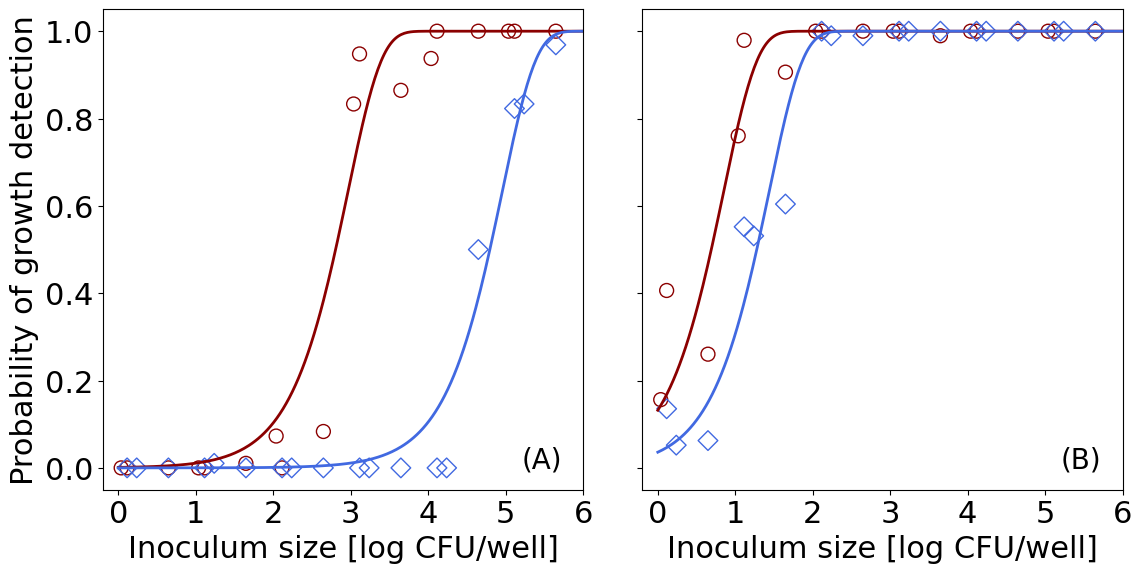

In [ ]:
### Exponential model by least squared method for E. coli data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

# loss function
def loss(p, n, y):
    pred = exponential_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    # (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    # (df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    (df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    # (df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    # (df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    (df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=[0.001],
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_3 = res_lower_3.x[0]
print(f"推定されたp(lower, Day3): {p_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = exponential_model(n_lower_3, p_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=[0.001],
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_3 = res_higher_3.x[0]
print(f"推定されたp(higher, day3): {p_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = exponential_model(n_higher_3, p_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = exponential_model(n_plot_lower_3, p_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = exponential_model(n_plot_higher_3, p_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=[0.001],
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_7 = res_lower_7.x[0]
print(f"推定されたp(lower, day7): {p_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = exponential_model(n_lower_7, p_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=[0.001],
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_7 = res_higher_7.x[0]
print(f"推定されたp(higher, Day7): {p_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = exponential_model(n_higher_7, p_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = exponential_model(n_plot_lower_7, p_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = exponential_model(n_plot_higher_7, p_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


推定されたp(lower, Day3): 0.00615
RMSE (lower, Day3): 0.06553
推定されたp(higher, day3): 0.00006
RMSE (higher, Day3): 0.04983
推定されたp(lower, day7): 0.06098
RMSE (lower, Day7): 0.05703
推定されたp(higher, Day7): 0.00010
RMSE (higher, Day7): 0.02820


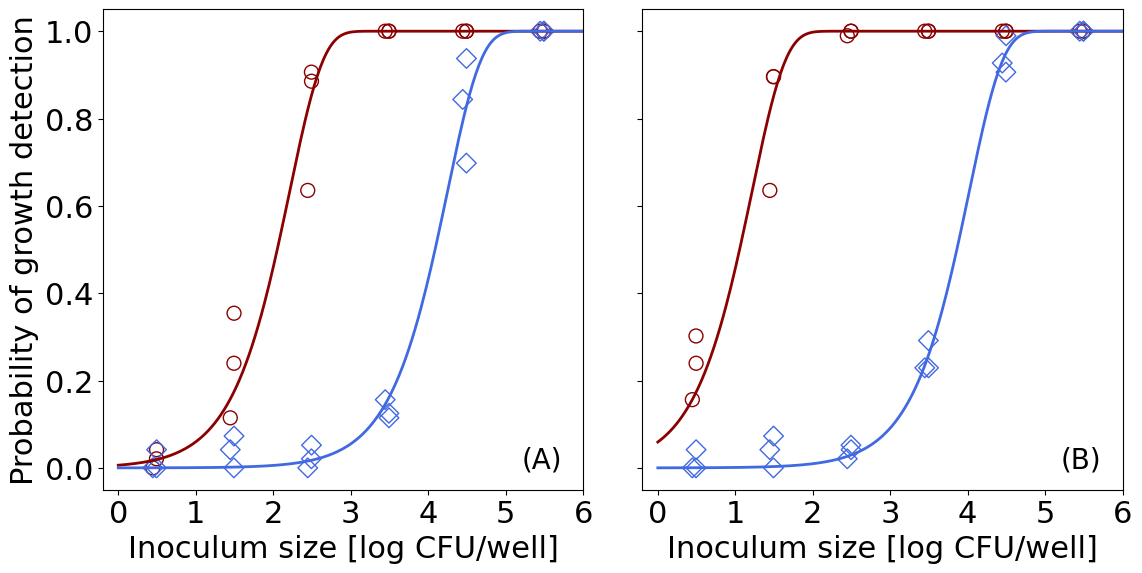

In [6]:
### Exponential model by least squared method for B. cereus data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

# loss function
def loss(p, n, y):
    pred = exponential_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=[0.001],
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_3 = res_lower_3.x[0]
print(f"推定されたp(lower, Day3): {p_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = exponential_model(n_lower_3, p_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=[0.001],
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_3 = res_higher_3.x[0]
print(f"推定されたp(higher, day3): {p_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = exponential_model(n_higher_3, p_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = exponential_model(n_plot_lower_3, p_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = exponential_model(n_plot_higher_3, p_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=[0.001],
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_7 = res_lower_7.x[0]
print(f"推定されたp(lower, day7): {p_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = exponential_model(n_lower_7, p_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=[0.001],
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_7 = res_higher_7.x[0]
print(f"推定されたp(higher, Day7): {p_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = exponential_model(n_higher_7, p_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = exponential_model(n_plot_lower_7, p_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = exponential_model(n_plot_higher_7, p_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Exponential_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


推定されたp(NaCl 6.5 %): 0.00109
RMSE (NaCl 6.5 %): 0.10176
推定されたp(NaCl 7.0 %): 0.00001
RMSE (NaCl 7.0 %): 0.06163


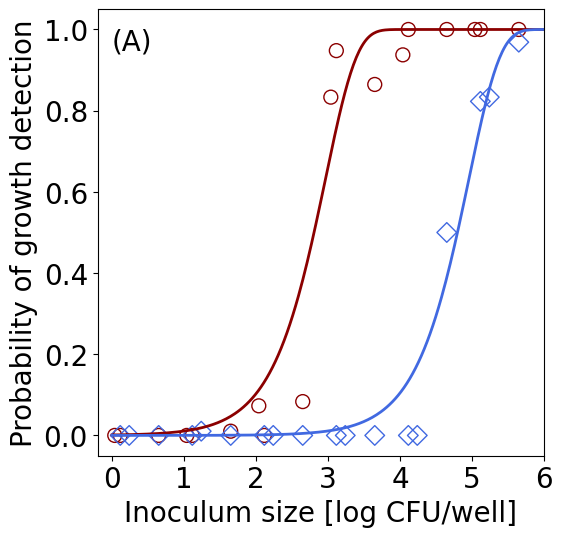

In [8]:
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

# loss function
def loss(p, n, y):
    pred = exponential_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## E.coli, NaCl, Day3
# 6.5%(w/v)
df_Ec_NaCl_65_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    (df_all["NaCl_[w/v_%]"] == 6.5) #18
    #(df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# 7.0%(w/v)
df_Ec_NaCl_70_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    # (df_all["NaCl_[w/v_%]"] == 6.5) #18
    (df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Ec_NaCl_65_day3["Growth_probability"] = df_Ec_NaCl_65_day3["Number_of_growth_well"] / 96
df_Ec_NaCl_65_day3["Inoculum_size"] = df_Ec_NaCl_65_day3["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_65_day3 = df_Ec_NaCl_65_day3.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Ec_NaCl_70_day3["Growth_probability"] = df_Ec_NaCl_70_day3["Number_of_growth_well"] / 96
df_Ec_NaCl_70_day3["Inoculum_size"] = df_Ec_NaCl_70_day3["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_70_day3 = df_Ec_NaCl_70_day3.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_65 = df_Ec_NaCl_65_day3["Inoculum_size"].values
y_65 = df_Ec_NaCl_65_day3["Growth_probability"].values
res_65 = minimize(loss, x0=[0.001], args=(n_65, y_65), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_65 = res_65.x[0]
print(f"推定されたp(NaCl 6.5 %): {p_hat_65:.5f}")
# NaCl 6.5% のRMSE
pred_65 = single_hit_model(n_65, p_hat_65)
rmse_65 = np.sqrt(np.mean((pred_65 - y_65) ** 2))
print(f"RMSE (NaCl 6.5 %): {rmse_65:.5f}")

n_70 = df_Ec_NaCl_70_day3["Inoculum_size"].values
y_70 = df_Ec_NaCl_70_day3["Growth_probability"].values
res_70 = minimize(loss, x0=[0.001], args=(n_70, y_70), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_70 = res_70.x[0]
print(f"推定されたp(NaCl 7.0 %): {p_hat_70:.5f}")
# NaCl 7.0% のRMSE
pred_70 = single_hit_model(n_70, p_hat_70)
rmse_70 = np.sqrt(np.mean((pred_70 - y_70) ** 2))
print(f"RMSE (NaCl 7.0 %): {rmse_70:.5f}")

# fitting to single-hit model
n_plot_65 = np.logspace(0, 6, 300)
y_plot_65 = single_hit_model(n_plot_65, p_hat_65)

n_plot_70 = np.logspace(0, 6, 300)
y_plot_70 = single_hit_model(n_plot_70, p_hat_70)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_65), y_65, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_65), y_plot_65, color='darkred', lw=2)
ax.scatter(np.log10(n_70), y_70, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_70), y_plot_70, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(0,0.95, '(A)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_3day_ver2025Oct31st.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_3day_transparent_ver2025Oct31st.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

推定されたp(NaCl 6.5 %): 0.14148
RMSE (NaCl 6.5 %): 0.08489
推定されたp(NaCl 7.0 %): 0.00001
RMSE (NaCl 7.0 %): 0.06163


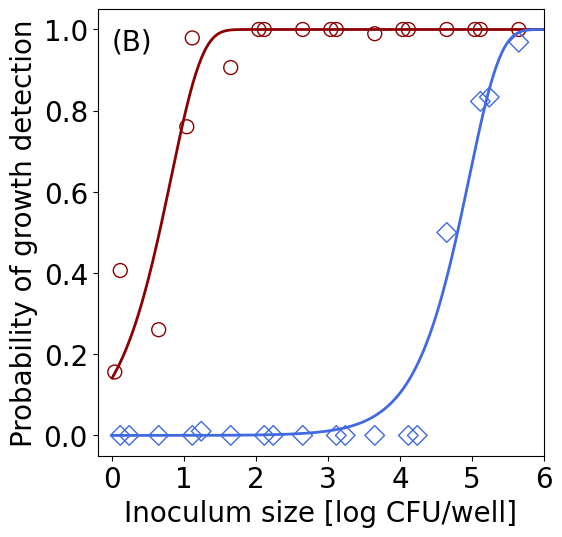

In [9]:
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def exponential_model(n, p):
    return 1 - np.exp(-n * p)  # P(growth | dose=n)

# loss function
def loss(p, n, y):
    pred = exponential_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## E.coli, NaCl, Day7
# 6.5%(w/v)
df_Ec_NaCl_65_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    (df_all["NaCl_[w/v_%]"] == 6.5) #18
    #(df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# 7.0%(w/v)
df_Ec_NaCl_70_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    # (df_all["NaCl_[w/v_%]"] == 6.5) #18
    (df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Ec_NaCl_65_day7["Growth_probability"] = df_Ec_NaCl_65_day7["Number_of_growth_well"] / 96
df_Ec_NaCl_65_day7["Inoculum_size"] = df_Ec_NaCl_65_day7["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_65_day7 = df_Ec_NaCl_65_day7.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Ec_NaCl_70_day7["Growth_probability"] = df_Ec_NaCl_70_day7["Number_of_growth_well"] / 96
df_Ec_NaCl_70_day7["Inoculum_size"] = df_Ec_NaCl_70_day7["Inoculum_size_[CFU/well]"]
df_Ec_NaCl_70_day7 = df_Ec_NaCl_70_day7.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_65 = df_Ec_NaCl_65_day7["Inoculum_size"].values
y_65 = df_Ec_NaCl_65_day7["Growth_probability"].values
res_65 = minimize(loss, x0=[0.001], args=(n_65, y_65), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_65 = res_65.x[0]
print(f"推定されたp(NaCl 6.5 %): {p_hat_65:.5f}")
# NaCl 6.5% のRMSE
pred_65 = single_hit_model(n_65, p_hat_65)
rmse_65 = np.sqrt(np.mean((pred_65 - y_65) ** 2))
print(f"RMSE (NaCl 6.5 %): {rmse_65:.5f}")

n_70 = df_Ec_NaCl_70_day7["Inoculum_size"].values
y_70 = df_Ec_NaCl_70_day7["Growth_probability"].values
res_70 = minimize(loss, x0=[0.001], args=(n_70, y_70), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_70 = res_70.x[0]
print(f"推定されたp(NaCl 7.0 %): {p_hat_70:.5f}")
# NaCl 7.0% のRMSE
pred_70 = single_hit_model(n_70, p_hat_70)
rmse_70 = np.sqrt(np.mean((pred_70 - y_70) ** 2))
print(f"RMSE (NaCl 7.0 %): {rmse_70:.5f}")

# fitting to single-hit model
n_plot_65 = np.logspace(0, 6, 300)
y_plot_65 = single_hit_model(n_plot_65, p_hat_65)

n_plot_70 = np.logspace(0, 6, 300)
y_plot_70 = single_hit_model(n_plot_70, p_hat_70)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_65), y_65, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_65), y_plot_65, color='darkred', lw=2)
ax.scatter(np.log10(n_70), y_70, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_70), y_plot_70, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(0,0.95, '(B)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_1week_ver2025Oct31st.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_1week_transparent_ver2025Oct31st.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

# Beta-Poisson model

推定されたalpha,beta(lower, Day3): 4.63620, 145093.80281
RMSE (lower, Day3): 0.04263
推定されたalpha,beta(higher, Day3): 896.40809, 103147011.33284
RMSE (higher, Day3): 0.02377
推定されたalpha,beta(lower, day7): 4.60521, 124816.12058
RMSE (lower, Day7): 0.04163
推定されたalpha,beta(higher, Day7): 10.39189, 996507.11851
RMSE (higher, Day7): 0.01976


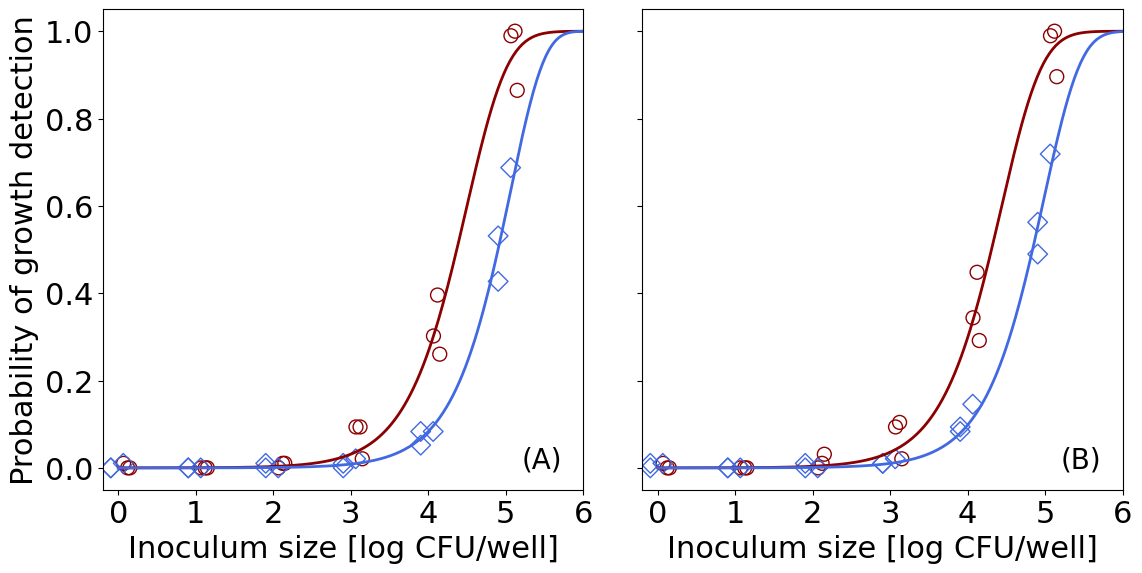

In [10]:
### Beta-Poisson model by least squared method for E. coli data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def beta_poisson_model(n, alpha, beta):
    return 1 - (1 + n/beta) ** (-alpha)  

# loss function
def loss(params, n, y):
    alpha, beta = params
    pred = beta_poisson_model(n, alpha, beta)
    return np.sum((pred - y) ** 2)

# initial value foralpha, beta
x0 = [0.1, 10.0]
# alpha > 0, beta > 0 
bounds = ((1e-8, None), (1e-8, None),)


df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


推定されたalpha,beta(lower, Day3): 1.74549, 442.32057
RMSE (lower, Day3): 0.11650
推定されたalpha,beta(higher, Day3): 15.05186, 151705.53019
RMSE (higher, Day3): 0.10142
推定されたalpha,beta(lower, day7): 2.52215, 0.59806
RMSE (lower, Day7): 0.04598
推定されたalpha,beta(higher, Day7): 0.84423, 1.65294
RMSE (higher, Day7): 0.05907


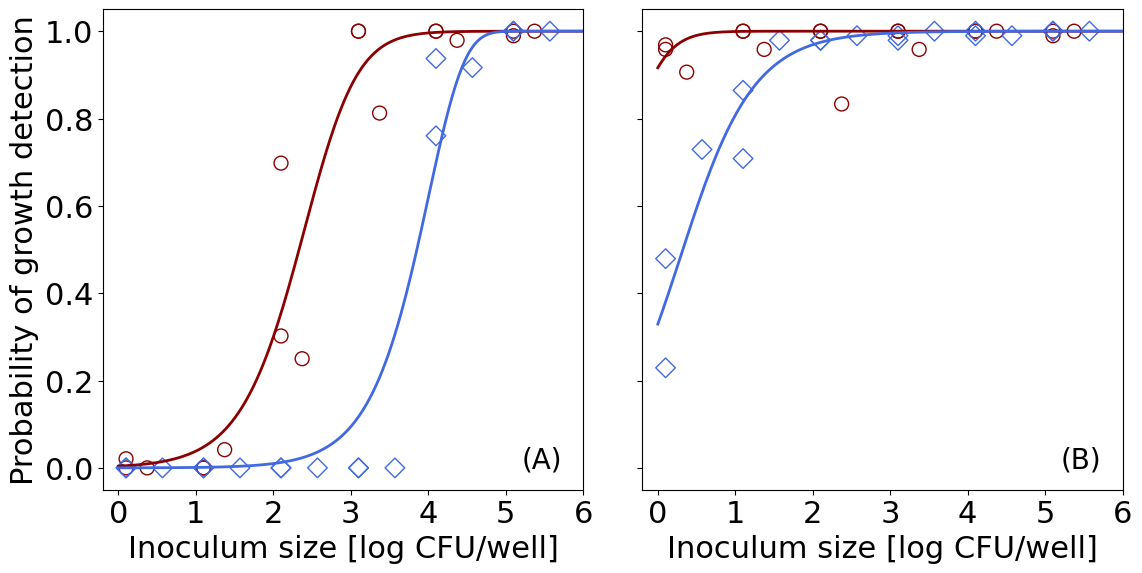

In [11]:
### Beta-Poisson model by least squared method for B. cereus data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def beta_poisson_model(n, alpha, beta):
    return 1 - (1 + n/beta) ** (-alpha)  

# loss function
def loss(params, n, y):
    alpha, beta = params
    pred = beta_poisson_model(n, alpha, beta)
    return np.sum((pred - y) ** 2)

# initial value foralpha, beta
x0 = [0.1, 10.0]
# alpha > 0, beta > 0 
bounds = ((1e-8, None), (1e-8, None),)


df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    # (df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    # (df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    # (df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    # (df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()


# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


# logistic regression model

推定されたa0,a1(lower, Day3): -14.64685, 1.47075
RMSE (lower, Day3): 0.04698
推定されたa0,a1(higher, Day3): -14.66408, 1.30274
RMSE (higher, Day3): 0.02647
推定されたa0,a1(lower, day7): -14.06599, 1.42931
RMSE (lower, Day7): 0.04684
推定されたa0,a1(higher, Day7): -12.41976, 1.12103
RMSE (higher, Day7): 0.02284


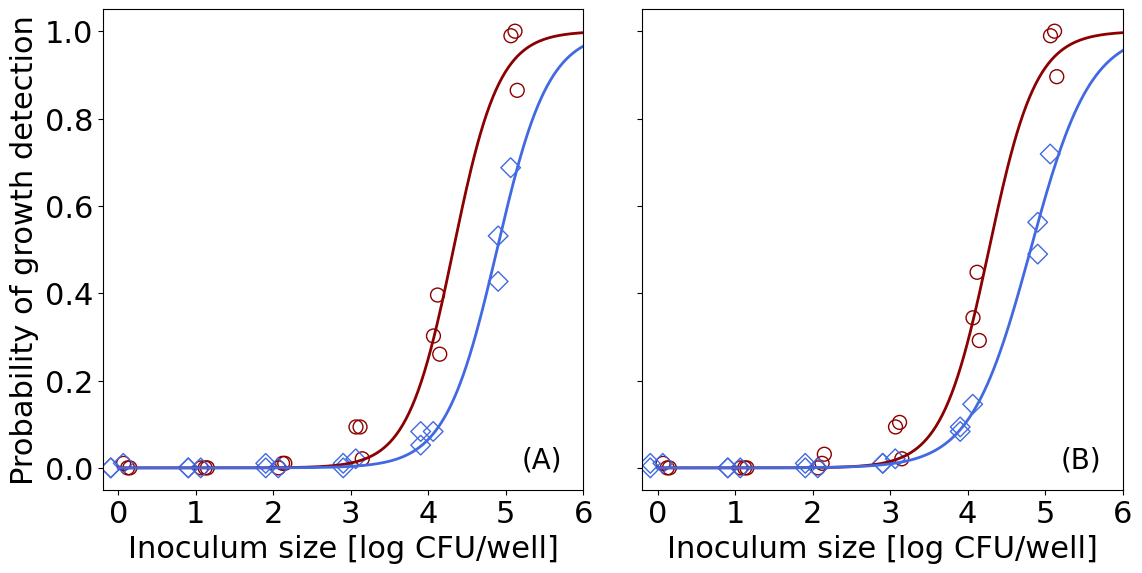

In [12]:
### logistic regression model by least squared method for E. coli data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def logistic_regression_model(n, a0, a1):
    return 1/(1 + np.exp(-(a0 + a1*np.log(n))))

# loss function
def loss(params, n, y):
    a0, a1 = params
    pred = logistic_regression_model(n, a0, a1)
    return np.sum((pred - y) ** 2)

# initial value for a0, a1
def init_logistic_params(n, y):
    n = np.asarray(n)
    y = np.asarray(y)
    # cliping y
    y_clipped = np.clip(y, 1e-6, 1 - 1e-6)
    # calcurating log_n, log_y 
    log_n = np.log(n)
    logit_y = np.log(y_clipped / (1 - y_clipped))
    # excluding missing & infinite value
    mask = np.isfinite(log_n) & np.isfinite(logit_y)
    log_n = log_n[mask]
    logit_y = logit_y[mask]
    # fitting "logit_y ≒ a0 + a1*log_n" by least squared method
    X = np.vstack([np.ones_like(log_n), log_n]).T  
    params, *_ = np.linalg.lstsq(X, logit_y, rcond=None)
    a0_init, a1_init = params
    bounds = ((None, None), (None, None),)
    return np.array([a0_init, a1_init]), bounds

df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
x0_lower_3, bounds_lower_3 = init_logistic_params(n_lower_3, y_lower_3)
res_lower_3 = minimize(loss, x0=x0_lower_3,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds_lower_3)
a0_hat_lower_3, a1_hat_lower_3 = res_lower_3.x
print(f"推定されたa0,a1(lower, Day3): {a0_hat_lower_3:.5f}, {a1_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = logistic_regression_model(n_lower_3, a0_hat_lower_3, a1_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
x0_higher_3, bounds_higher_3 =init_logistic_params(n_higher_3, y_higher_3)
res_higher_3 = minimize(loss, x0=x0_higher_3,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds_higher_3)
a0_hat_higher_3, a1_hat_higher_3 = res_higher_3.x
print(f"推定されたa0,a1(higher, Day3): {a0_hat_higher_3:.5f}, {a1_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = logistic_regression_model(n_higher_3, a0_hat_higher_3, a1_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = logistic_regression_model(n_plot_lower_3, a0_hat_lower_3, a1_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = logistic_regression_model(n_plot_higher_3, a0_hat_higher_3, a1_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
x0_lower_7, bounds_lower_7 = init_logistic_params(n_lower_7, y_lower_7)
res_lower_7 = minimize(loss, x0=x0_lower_7,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds_lower_7)
a0_hat_lower_7, a1_hat_lower_7 = res_lower_7.x
print(f"推定されたa0,a1(lower, day7): {a0_hat_lower_7:.5f}, {a1_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = logistic_regression_model(n_lower_7, a0_hat_lower_7, a1_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
x0_higher_7, bounds_higher_7 = init_logistic_params(n_higher_7, y_higher_7)
res_higher_7 = minimize(loss, x0=x0_higher_7,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds_higher_7)
a0_hat_higher_7, a1_hat_higher_7 = res_higher_7.x
print(f"推定されたa0,a1(higher, Day7): {a0_hat_higher_7:.5f}, {a1_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = logistic_regression_model(n_higher_7, a0_hat_higher_7, a1_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = logistic_regression_model(n_plot_lower_7, a0_hat_lower_7, a1_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = logistic_regression_model(n_plot_higher_7, a0_hat_higher_7, a1_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


推定されたa0,a1(lower, Day3): -5.11864, 1.15466
RMSE (lower, Day3): 0.05962
推定されたa0,a1(higher, Day3): -13.82894, 1.49284
RMSE (higher, Day3): 0.04924
推定されたa0,a1(lower, day7): -2.48523, 1.15899
RMSE (lower, Day7): 0.05100
推定されたa0,a1(higher, Day7): -14.23099, 1.64153
RMSE (higher, Day7): 0.03129


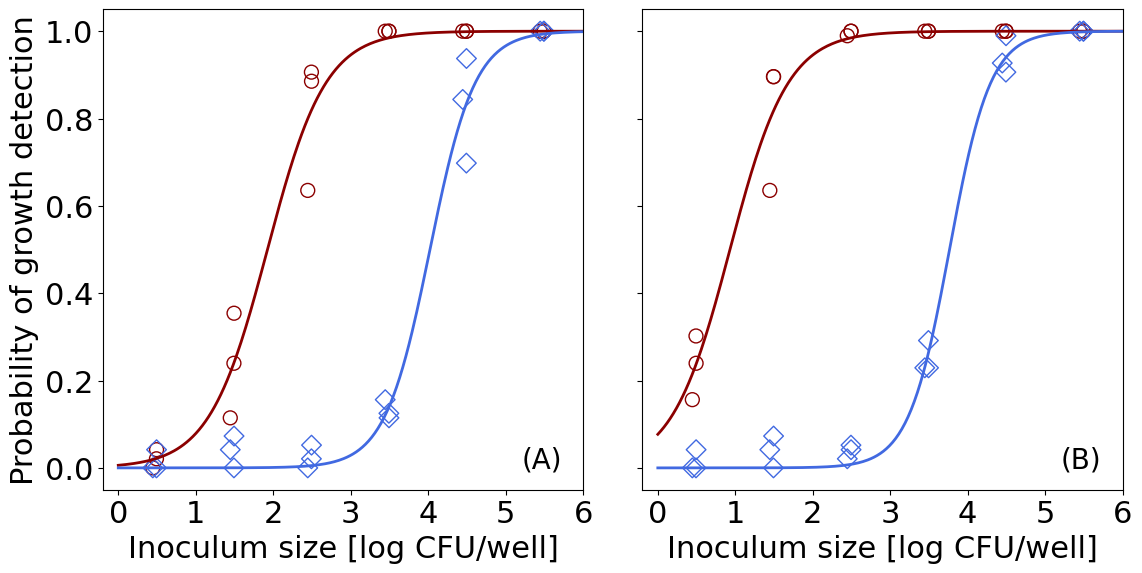

In [13]:
### logistic regression model by least squared method for B. cereus data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def logistic_regression_model(n, a0, a1):
    return 1/(1 + np.exp(-(a0 + a1*np.log(n))))

# loss function
def loss(params, n, y):
    a0, a1 = params
    pred = logistic_regression_model(n, a0, a1)
    return np.sum((pred - y) ** 2)

# initial value for a0, a1
def init_logistic_params(n, y):
    n = np.asarray(n)
    y = np.asarray(y)
    # cliping y
    y_clipped = np.clip(y, 1e-6, 1 - 1e-6)
    # calcurating log_n, log_y 
    log_n = np.log(n)
    logit_y = np.log(y_clipped / (1 - y_clipped))
    # excluding missing & infinite value
    mask = np.isfinite(log_n) & np.isfinite(logit_y)
    log_n = log_n[mask]
    logit_y = logit_y[mask]
    # fitting "logit_y ≒ a0 + a1*log_n" by least squared method
    X = np.vstack([np.ones_like(log_n), log_n]).T  
    params, *_ = np.linalg.lstsq(X, logit_y, rcond=None)
    a0_init, a1_init = params
    bounds = ((None, None), (None, None),)
    return np.array([a0_init, a1_init]), bounds

df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
x0_lower_3, bounds_lower_3 = init_logistic_params(n_lower_3, y_lower_3)
res_lower_3 = minimize(loss, x0=x0_lower_3,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds_lower_3)
a0_hat_lower_3, a1_hat_lower_3 = res_lower_3.x
print(f"推定されたa0,a1(lower, Day3): {a0_hat_lower_3:.5f}, {a1_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = logistic_regression_model(n_lower_3, a0_hat_lower_3, a1_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
x0_higher_3, bounds_higher_3 = init_logistic_params(n_higher_3, y_higher_3)
res_higher_3 = minimize(loss, x0=x0_higher_3,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds_higher_3)
a0_hat_higher_3, a1_hat_higher_3 = res_higher_3.x
print(f"推定されたa0,a1(higher, Day3): {a0_hat_higher_3:.5f}, {a1_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = logistic_regression_model(n_higher_3, a0_hat_higher_3, a1_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = logistic_regression_model(n_plot_lower_3, a0_hat_lower_3, a1_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = logistic_regression_model(n_plot_higher_3, a0_hat_higher_3, a1_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
x0_lower_7, bounds_lower_7 = init_logistic_params(n_lower_7, y_lower_7)
res_lower_7 = minimize(loss, x0=x0_lower_7,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds_lower_7)
a0_hat_lower_7, a1_hat_lower_7 = res_lower_7.x
print(f"推定されたa0,a1(lower, day7): {a0_hat_lower_7:.5f}, {a1_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = logistic_regression_model(n_lower_7, a0_hat_lower_7, a1_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
x0_higher_7, bounds_higher_7 = init_logistic_params(n_higher_7, y_higher_7)
res_higher_7 = minimize(loss, x0=x0_higher_7,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds_higher_7)
a0_hat_higher_7, a1_hat_higher_7 = res_higher_7.x
print(f"推定されたa0,a1(higher, Day7): {a0_hat_higher_7:.5f}, {a1_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = logistic_regression_model(n_higher_7, a0_hat_higher_7, a1_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = logistic_regression_model(n_plot_lower_7, a0_hat_lower_7, a1_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = logistic_regression_model(n_plot_higher_7, a0_hat_higher_7, a1_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_Logistic_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


## Single-hit model

推定されたp(lower, Day3): 0.00003
RMSE (lower, Day3): 0.04368
推定されたp(higher, day3): 0.00001
RMSE (higher, Day3): 0.02685
推定されたp(lower, day7): 0.00003
RMSE (lower, Day7): 0.04292
推定されたp(higher, Day7): 0.00001
RMSE (higher, Day7): 0.01967


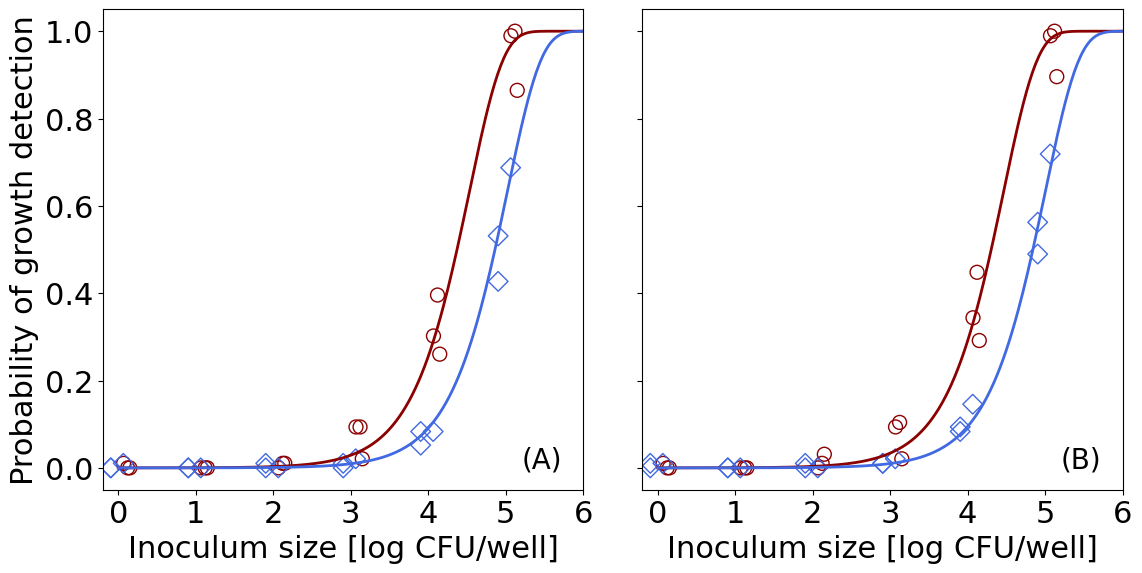

In [14]:
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    # (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    #(df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    #(df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
    # (df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Ec_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=[0.001],
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_3 = res_lower_3.x[0]
print(f"推定されたp(lower, Day3): {p_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = single_hit_model(n_lower_3, p_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=[0.001],
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_3 = res_higher_3.x[0]
print(f"推定されたp(higher, day3): {p_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = single_hit_model(n_higher_3, p_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = single_hit_model(n_plot_lower_3, p_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = single_hit_model(n_plot_higher_3, p_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=[0.001],
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_7 = res_lower_7.x[0]
print(f"推定されたp(lower, day7): {p_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = single_hit_model(n_lower_7, p_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=[0.001],
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_7 = res_higher_7.x[0]
print(f"推定されたp(higher, Day7): {p_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = single_hit_model(n_higher_7, p_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = single_hit_model(n_plot_lower_7, p_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = single_hit_model(n_plot_higher_7, p_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

推定されたp(lower, Day3): 0.00305
RMSE (lower, Day3): 0.11864
推定されたp(higher, day3): 0.00010
RMSE (higher, Day3): 0.09994
推定されたp(lower, day7): 0.91953
RMSE (lower, Day7): 0.04701
推定されたp(higher, Day7): 0.26918
RMSE (higher, Day7): 0.08311


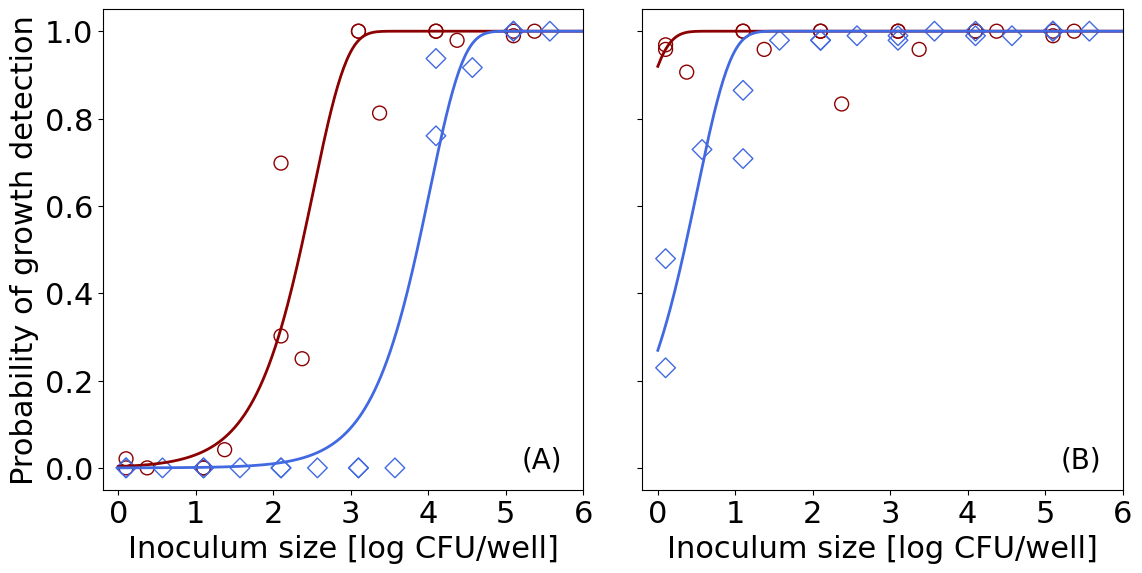

In [15]:
### SingleHit model by least squared method for B. cereus data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    # (df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    #(df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
    # (df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day3["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    # (df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    #(df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    #(df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
    # (df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
    # (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_Bc_day7["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=[0.001],
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_3 = res_lower_3.x[0]
print(f"推定されたp(lower, Day3): {p_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = single_hit_model(n_lower_3, p_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=[0.001],
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_3 = res_higher_3.x[0]
print(f"推定されたp(higher, day3): {p_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = single_hit_model(n_higher_3, p_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = single_hit_model(n_plot_lower_3, p_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = single_hit_model(n_plot_higher_3, p_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=[0.01],
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_lower_7 = res_lower_7.x[0]
print(f"推定されたp(lower, day7): {p_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = single_hit_model(n_lower_7, p_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=[0.01],
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=((0.0, 1.0),))
p_hat_higher_7 = res_higher_7.x[0]
print(f"推定されたp(higher, Day7): {p_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = single_hit_model(n_higher_7, p_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = single_hit_model(n_plot_lower_7, p_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = single_hit_model(n_plot_higher_7, p_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()

## Saving Figures
### Glycine
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
### NaCl
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_SingleHit_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


## Visualizing individually

### _E. coli_ ((A) Day3, (B) Day7)

推定されたp(lower): 0.00109
RMSE (lower): 0.10176
推定されたp(higher): 0.00001
RMSE (higher): 0.06163


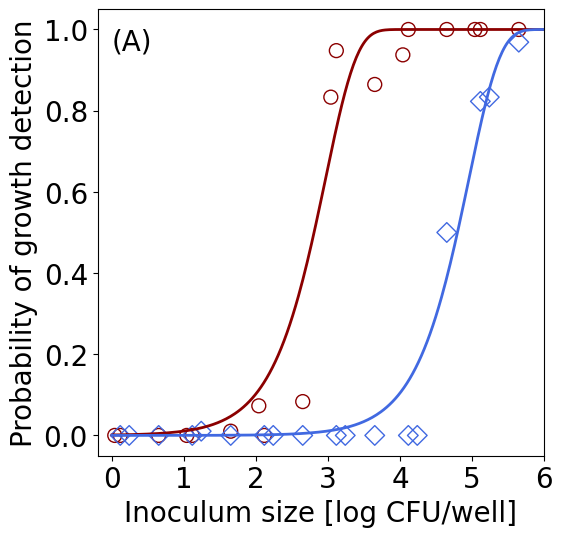

In [17]:
# Figure for E. coli Day3

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
# lower stress
df_Ec_lower_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    (df_all["NaCl_[w/v_%]"] == 6.5) #18
    #(df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress
df_Ec_higher_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    # (df_all["NaCl_[w/v_%]"] == 6.5) #18
    (df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_lower = df_Ec_lower_day3["Inoculum_size"].values
y_lower = df_Ec_lower_day3["Growth_probability"].values
res_lower = minimize(loss, x0=[0.001], args=(n_lower, y_lower), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_lower = res_lower.x[0]
print(f"推定されたp(lower): {p_hat_lower:.5f}")
# lower additive stress のRMSE
pred_lower = single_hit_model(n_lower, p_hat_lower)
rmse_lower = np.sqrt(np.mean((pred_lower - y_lower) ** 2))
print(f"RMSE (lower): {rmse_lower:.5f}")

n_higher = df_Ec_higher_day3["Inoculum_size"].values
y_higher = df_Ec_higher_day3["Growth_probability"].values
res_higher = minimize(loss, x0=[0.001], args=(n_higher, y_higher), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_higher = res_higher.x[0]
print(f"推定されたp(higher): {p_hat_higher:.5f}")
# higher additive stress のRMSE
pred_higher = single_hit_model(n_higher, p_hat_higher)
rmse_higher = np.sqrt(np.mean((pred_higher - y_higher) ** 2))
print(f"RMSE (higher): {rmse_higher:.5f}")

# fitting to single-hit model
n_plot_lower = np.logspace(0, 6, 300)
y_plot_lower = single_hit_model(n_plot_lower, p_hat_lower)

n_plot_higher = np.logspace(0, 6, 300)
y_plot_higher = single_hit_model(n_plot_higher, p_hat_higher)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Glycine 1.7%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Ethanol 5.6%(v/v)")
ax.plot(np.log10(n_plot_lower), y_plot_lower, color='darkred', lw=2)
ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Glycine 1.8%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Ethanol 6.0%(v/v)")
ax.plot(np.log10(n_plot_higher), y_plot_higher, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(0,0.95, '(A)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()

### save figures for E. coli at Day3
## NaCl
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_3day_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_3day_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Glycine
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Gly_17_18_3day_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Gly_17_18_3day_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Ethanol
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Etha_56_60_3day_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Etha_56_60_3day_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)


推定されたp(lower): 0.13193
RMSE (lower): 0.08422
推定されたp(higher): 0.03596
RMSE (higher): 0.07049


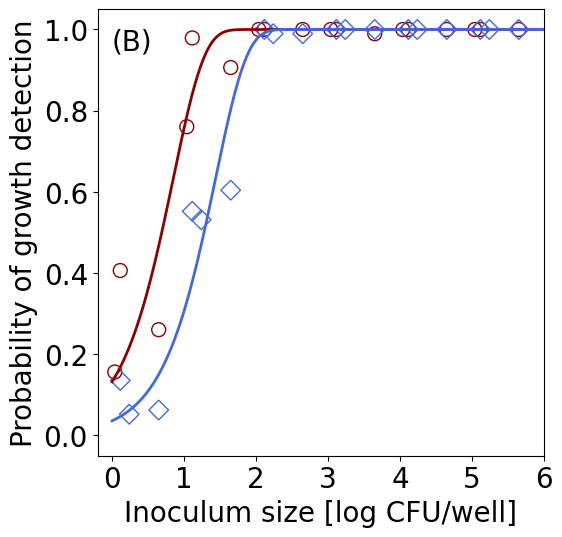

In [18]:
# Figure for E. coli Day7

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
# lower stress
df_Ec_lower_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    (df_all["NaCl_[w/v_%]"] == 6.5) #18
    #(df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()
# higher stress
df_Ec_higher_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7) &
    #(df["Glycine_[w/v_%]"] == 1.7) #18
    #(df["Glycine_[w/v_%]"] == 1.8) #18
    # (df_all["NaCl_[w/v_%]"] == 6.5) #18
    (df_all["NaCl_[w/v_%]"] == 7.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.0) #18
    #(df_all["Ethanol_[v/v_%]"] == 5.6) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_lower = df_Ec_lower_day7["Inoculum_size"].values
y_lower = df_Ec_lower_day7["Growth_probability"].values
res_lower = minimize(loss, x0=[0.001], args=(n_lower, y_lower), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_lower = res_lower.x[0]
print(f"推定されたp(lower): {p_hat_lower:.5f}")
# NaCl 6.5% のRMSE
pred_lower = single_hit_model(n_lower, p_hat_lower)
rmse_lower = np.sqrt(np.mean((pred_lower - y_lower) ** 2))
print(f"RMSE (lower): {rmse_lower:.5f}")

n_higher = df_Ec_higher_day7["Inoculum_size"].values
y_higher = df_Ec_higher_day7["Growth_probability"].values
res_higher = minimize(loss, x0=[0.001], args=(n_higher, y_higher), method="L-BFGS-B", bounds=((0.0, 1.0),))
p_hat_higher = res_higher.x[0]
print(f"推定されたp(higher): {p_hat_higher:.5f}")
# NaCl 7.0% のRMSE
pred_higher = single_hit_model(n_higher, p_hat_higher)
rmse_higher = np.sqrt(np.mean((pred_higher - y_higher) ** 2))
print(f"RMSE (higher): {rmse_higher:.5f}")

# fitting to single-hit model
n_plot_lower = np.logspace(0, 6, 300)
y_plot_lower = single_hit_model(n_plot_lower, p_hat_lower)

n_plot_higher = np.logspace(0, 6, 300)
y_plot_higher = single_hit_model(n_plot_higher, p_hat_higher)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Glycine 1.7%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Ethanol 5.6%(v/v)")
ax.plot(np.log10(n_plot_lower), y_plot_lower, color='darkred', lw=2)
ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Glycine 1.8%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Ethanol 6.0%(v/v)")
ax.plot(np.log10(n_plot_higher), y_plot_higher, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(0,0.95, '(B)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()

### save figures for E. coli at Day7
## NaCl
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_1week_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_NaCl_65_70_1week_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Glycine
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Gly_17_18_1week_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Gly_17_18_1week_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Ethanol
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Etha_56_60_1week_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Ecoli_Etha_56_60_1week_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

### _B. cereus_ ((A) Day3, (B) Day7)

推定されたp(lower): 0.00613
RMSE (lower): 0.06553
推定されたp(higher): 0.00006
RMSE (higher): 0.04983


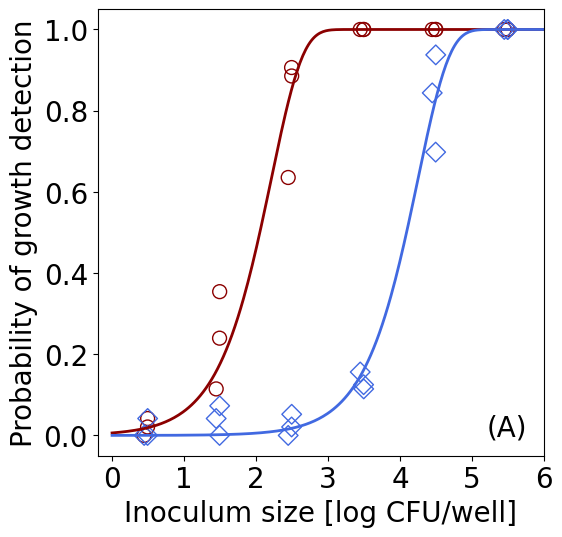

In [19]:
# Figure for B. cereus Day3

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
# lower stress
df_Bc_lower_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3) &
    (df["Glycine_[w/v_%]"] == 1.4) #18
    #(df["Glycine_[w/v_%]"] == 1.6) #18
    # (df_all["NaCl_[w/v_%]"] == 7) #18
    #(df_all["NaCl_[w/v_%]"] == 7.5) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.9) #18
    #(df_all["Ethanol_[v/v_%]"] == 7.3) #18
].copy()
# higher stress
df_Bc_higher_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3) &
    #(df["Glycine_[w/v_%]"] == 1.4) #18
    (df["Glycine_[w/v_%]"] == 1.6) #18
    # (df_all["NaCl_[w/v_%]"] == 7) #18
    #(df_all["NaCl_[w/v_%]"] == 7.5) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.9) #18
    #(df_all["Ethanol_[v/v_%]"] == 7.3) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_lower = df_Bc_lower_day3["Inoculum_size"].values
y_lower = df_Bc_lower_day3["Growth_probability"].values
res_lower = minimize(loss, x0=[0.001], args=(n_lower, y_lower), bounds=[(0, 1)])
p_hat_lower = res_lower.x[0]
print(f"推定されたp(lower): {p_hat_lower:.5f}")
# Glycine 1.4% のRMSE
pred_lower = single_hit_model(n_lower, p_hat_lower)
rmse_lower = np.sqrt(np.mean((pred_lower - y_lower) ** 2))
print(f"RMSE (lower): {rmse_lower:.5f}")

n_higher = df_Bc_higher_day3["Inoculum_size"].values
y_higher = df_Bc_higher_day3["Growth_probability"].values
res_higher = minimize(loss, x0=[0.001], args=(n_higher, y_higher), bounds=[(0, 1)])
p_hat_higher = res_higher.x[0]
print(f"推定されたp(higher): {p_hat_higher:.5f}")
# Glycine 1.6% のRMSE
pred_higher = single_hit_model(n_higher, p_hat_higher)
rmse_higher = np.sqrt(np.mean((pred_higher - y_higher) ** 2))
print(f"RMSE (higher): {rmse_higher:.5f}")

# fitting to single-hit model
n_plot_lower = np.logspace(0, 6, 300)
y_plot_lower = single_hit_model(n_plot_lower, p_hat_lower)

n_plot_higher = np.logspace(0, 6, 300)
y_plot_higher = single_hit_model(n_plot_higher, p_hat_higher)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="lower")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Glycine 1.4%(w/v)")
ax.plot(np.log10(n_plot_lower), y_plot_lower, color='darkred', lw=2)
ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="higher")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Glycine 1.6%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher), y_plot_higher, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(5.2,0, '(A)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()

### save figures for E. coli at Day3
## NaCl
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_NaCl_70_75_3day_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_NaCl_70_75_3day_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Glycine
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_Glycine_14_16_3day_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_Glycine_14_16_3day_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

推定されたp(lower): 0.91953
RMSE (lower): 0.04701
推定されたp(higher): 0.26918
RMSE (higher): 0.08311


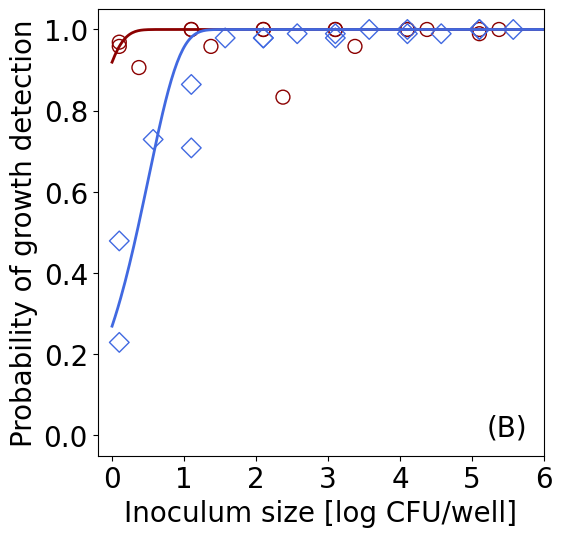

In [ ]:
# Figure for B. cereus Day7

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 20

# model definition
def single_hit_model(n, p):
    return 1 - (1 - p) ** n

# loss function
def loss(p, n, y):
    pred = single_hit_model(n, p[0])
    return np.sum((pred - y) ** 2)


df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day7
# lower stress
df_Bc_lower_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7) &
    #(df["Glycine_[w/v_%]"] == 1.4) #18
    #(df["Glycine_[w/v_%]"] == 1.6) #18
    (df_all["NaCl_[w/v_%]"] == 7) #18
    #(df_all["NaCl_[w/v_%]"] == 7.5) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.9) #18
    #(df_all["Ethanol_[v/v_%]"] == 7.3) #18
].copy()
# higher stress
df_Bc_higher_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7) &
    #(df["Glycine_[w/v_%]"] == 1.4) #18
    #(df["Glycine_[w/v_%]"] == 1.6) #18
    # (df_all["NaCl_[w/v_%]"] == 7) #18
    (df_all["NaCl_[w/v_%]"] == 7.5) #18
    #(df_all["Ethanol_[v/v_%]"] == 6.9) #18
    #(df_all["Ethanol_[v/v_%]"] == 7.3) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])

df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])


# estimating "p"
n_lower = df_Bc_lower_day7["Inoculum_size"].values
y_lower = df_Bc_lower_day7["Growth_probability"].values
res_lower = minimize(loss, x0=[0.001], args=(n_lower, y_lower), bounds=[(0, 1)])
p_hat_lower = res_lower.x[0]
print(f"推定されたp(lower): {p_hat_lower:.5f}")
# NaCl 7.0% のRMSE
pred_lower = single_hit_model(n_lower, p_hat_lower)
rmse_lower = np.sqrt(np.mean((pred_lower - y_lower) ** 2))
print(f"RMSE (lower): {rmse_lower:.5f}")

n_higher = df_Bc_higher_day7["Inoculum_size"].values
y_higher = df_Bc_higher_day7["Growth_probability"].values
res_higher = minimize(loss, x0=[0.001], args=(n_higher, y_higher), bounds=[(0, 1)])
p_hat_higher = res_higher.x[0]
print(f"推定されたp(higher): {p_hat_higher:.5f}")
# NaCl 7.5% のRMSE
pred_higher = single_hit_model(n_higher, p_hat_higher)
rmse_higher = np.sqrt(np.mean((pred_higher - y_higher) ** 2))
print(f"RMSE (higher): {rmse_higher:.5f}")

# fitting to single-hit model
n_plot_lower = np.logspace(0, 6, 300)
y_plot_lower = single_hit_model(n_plot_lower, p_hat_lower)

n_plot_higher = np.logspace(0, 6, 300)
y_plot_higher = single_hit_model(n_plot_higher, p_hat_higher)

fig, ax = plt.subplots(figsize=(6, 6))


# plotting observated values & drawing regression curve
ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="lower")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 7.0%(w/v)")
# ax.scatter(np.log10(n_lower), y_lower, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="Glycine 1.4%(w/v)")
ax.plot(np.log10(n_plot_lower), y_plot_lower, color='darkred', lw=2)
ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="higher")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="Glycine 1.6%(w/v)")
# ax.scatter(np.log10(n_higher), y_higher, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.5%(w/v)")
ax.plot(np.log10(n_plot_higher), y_plot_higher, color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")     
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1)) 
ax.set_yticks(np.arange(0, 1.01, 0.2))
# plt.legend()
ax.text(5.2,0, '(B)', fontsize=20)

ax.set_box_aspect(1)
plt.tight_layout()
fig.patch.set_alpha(0)
plt.show()

### save figures for E. coli at Day7
## NaCl
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_NaCl_70_75_1week_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_NaCl_70_75_1week_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)
## Glycine
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_Glycine_14_16_1week_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fitting_SingleHit_Bcereus_Glycine_14_16_1week_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

